# 09 · 用真实数据和针对性的增强训练

**目的。**notebook 08 发现，上线的 CNN 的错误几乎都来自 MNIST 里少见的写法（带横的 7、开口的 4、竖直尾巴的 9 等），还有一个所有数字共有的差异：真实书写更直立、笔画粗细更统一（notebook 07）。这一本测试两种对策：

1. **倾斜和笔宽增强**：针对所有数字共有的差异。训练时给图像随机加水平错切（模拟不同的倾斜），并对合成的"游戏笔画"也随机改变笔宽。
2. **加入真实的触控笔数据**：Pendigits 训练部分（24 人，约 6000 个），在笔画层面做增强（随机旋转、错切、缩放、笔宽）后，按游戏的流程画成图。这些写法正是 MNIST 里缺少的。

**实验设计。**和上线模型完全相同的训练预算（16 轮 × 470 步 × 128，Adam + 余弦退火，label smoothing 0.1）和相同的网络结构，只改变数据：

| 方案 | MNIST（增强） | 合成的游戏笔画 | 真实触控笔 | 倾斜 / 笔宽增强 |
|---|---|---|---|---|
| **A** 上线配方 | 50% | 50% | — | — |
| **B** + 增强 | 50% | 50% | — | 有 |
| **C** + 真实数据 | 40% | 40% | 20% | — |
| **D** + 两者 | 40% | 40% | 20% | 有 |

每个方案**用两个随机种子各训练一次**，用来判断差别是真实的还是训练的随机波动。

**怎么挑、怎么报告。**方案按**验证数据**挑选：Pendigits 的验证部分（触控笔，6 人）和 Corr 的 `dev` 部分（手指，76 人）的平均准确率。两个**测试集**只在最后报告一次。Corr 数据（手指）**完全不参与训练**（按 3.4 节的决定），所以它同时衡量"换一种工具、换一群人"时的泛化。

In [1]:
import json, pickle, sys, time
from multiprocessing import Pool
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras

from fingermath import datasets, models, ship, evaluate, augstrokes

REAL = Path('../cache/real'); RESULTS = Path('../results'); MODEL_DIR = Path('../cache/models')
SEEDS = [42, 43]
EPOCHS, STEPS, BATCH, SMOOTHING = 16, 470, 128, 0.1         # the shipped model's budget (notebook 06)
plt.rcParams['figure.dpi'] = 110

## 1. 数据

- **MNIST 训练集**（6 万张），和上线配方一样做仿射、粗细、锐化增强。
- **合成的游戏笔画**：MNIST 的骨架用游戏的笔重新画（notebook 06 的 `ship_skel_train`，上线版流程 `area18`）。
- **真实触控笔**：Pendigits 训练部分（notebook 07 划分的 `train`，24 人）。
- **验证**：Pendigits `val`（触控笔，6 人）、Corr `dev`（手指，76 人）。
- **测试**：Pendigits `test`（触控笔，14 人）、Corr `test`（手指，177 人）；另外附上合成的 `pad_tmpl`，和以前的结果对照。

In [2]:
x_mn, y_mn, _, _ = datasets.load_mnist()
x_mn = x_mn.astype(np.float32) / 255
skel, y_skel = ship.skeleton_sets(None, None, 'skel_train', seed=1, pens=True)   # cached by notebook 06
x_skel = skel['area18']

d = np.load(REAL / 'real_digits.npz')
meta = pd.DataFrame({k: d[k] for k in ['source', 'device', 'writer', 'split']}); meta['label'] = d['y']
x_real = d['x'].astype(np.float32) / 255
with open(REAL / 'real_strokes.pkl', 'rb') as f:
    strokes = pickle.load(f)

def part(source, split):
    k = meta.index[(meta.source == source) & (meta.split == split)].to_numpy()
    return x_real[k], meta.label.to_numpy()[k]

tmpl = np.load('../cache/ship_tmpl_test.npz')
evalsets = {
    'val: pen (Pendigits val)': part('pendigits', 'val'),
    'val: finger (Corr dev)': part('corr', 'dev'),
    'test: pen (Pendigits test)': part('pendigits', 'test'),
    'test: finger (Corr test)': part('corr', 'test'),
    'synthetic pad_tmpl': (tmpl['area18'], tmpl['y']),
}
for k, (x, y) in evalsets.items():
    print(f'{k:28s} {len(y):6d}')
print('MNIST', x_mn.shape, '| synthetic strokes', x_skel.shape)

val: pen (Pendigits val)       1496
val: finger (Corr dev)         6057
test: pen (Pendigits test)     3498
test: finger (Corr test)      14017
synthetic pad_tmpl            10000
MNIST (60000, 28, 28) | synthetic strokes (60000, 28, 28)


## 2. 真实触控笔数据：笔画层面的增强

Pendigits 训练部分只有约 6000 个样本、24 个人，直接用很容易过拟合到这 24 个人身上。所以先在**笔画层面**做增强，再按游戏的流程画成图，每个样本生成 5 个版本（1 个原样 + 4 个随机变化）：

- 随机旋转 ±10°；
- 随机水平错切 ±0.35（模拟不同的倾斜）；
- 宽、高分别随机缩放 0.8–1.2；
- 随机笔宽 12–26（游戏是 18）。

增强函数在 `augstrokes.py`，和画图用同一套代码（`ship.to28`）。

(29990, 28, 28) 43 s


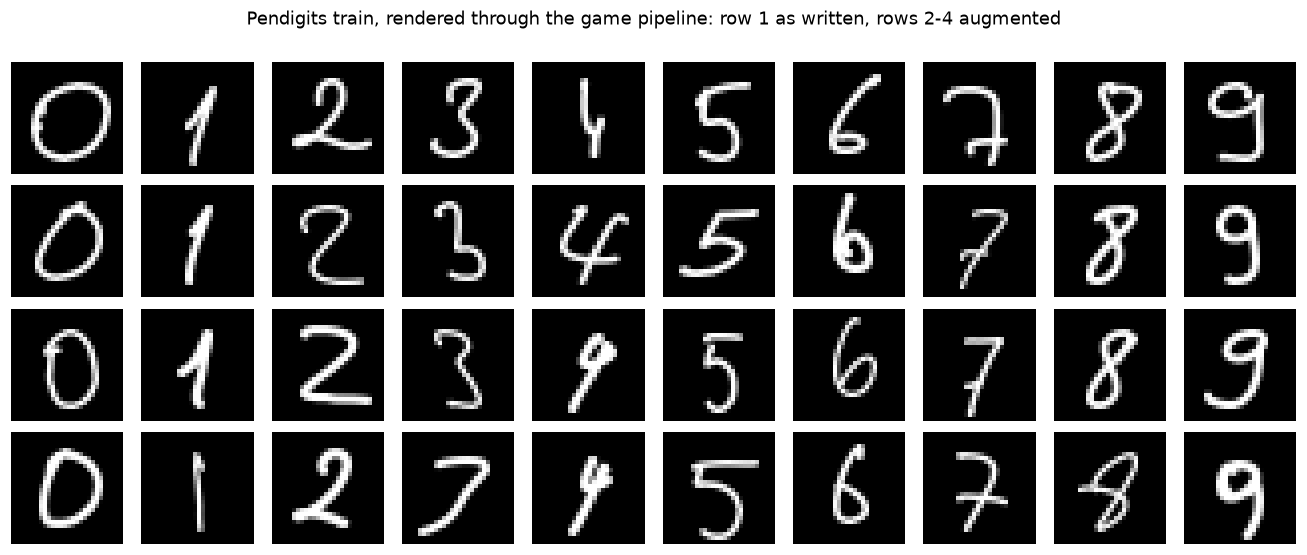

In [3]:
k_tr = meta.index[(meta.source == 'pendigits') & (meta.split == 'train')].to_numpy()
y_pen = meta.label.to_numpy()[k_tr]
tasks = [(strokes[i]['strokes'], 1000 + j) for j, i in enumerate(k_tr)]
t0 = time.time()
with Pool() as pool:
    renders = pool.starmap(augstrokes.render_variants, tasks, chunksize=100)   # 5 images per sample
x_pen = np.concatenate(renders).astype(np.float32)
y_pen5 = np.repeat(y_pen, 5)
print(x_pen.shape, f'{time.time() - t0:.0f} s')

fig, axes = plt.subplots(4, 10, figsize=(12, 5))
for r in range(4):
    for c in range(10):
        i = np.flatnonzero(y_pen == c)[r]
        axes[r, c].imshow(x_pen[i * 5 + r + 1 if r else i * 5], cmap='gray'); axes[r, c].axis('off')
fig.suptitle('Pendigits train, rendered through the game pipeline: row 1 as written, rows 2-4 augmented', y=1.0)
plt.tight_layout(); plt.show()

## 3. 图像层面的倾斜和笔宽增强（方案 B、D）

上线配方里，MNIST 有粗细增强，合成笔画只有轻微的仿射变换。方案 B、D 对**所有来源**都加上：

- 随机水平错切 ±0.3：让模型见到从左倾到右倾、包括完全直立的写法；
- 随机粗细（腐蚀 / 不变 / 膨胀）：笔画粗细不再是固定的。

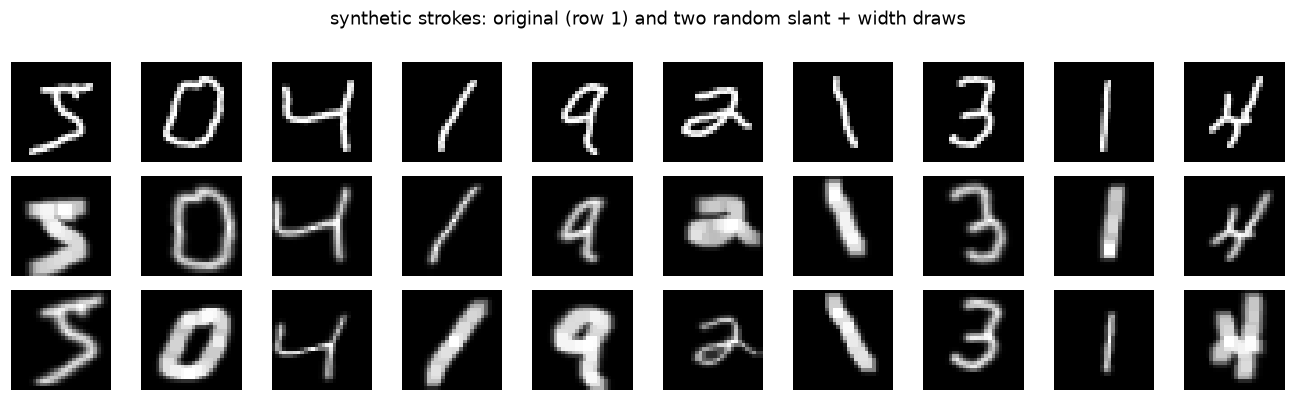

In [4]:
def random_shear(x, amount=0.3):
    """Horizontal shear about the image centre: x' = x + s * (y - 14), s ~ U(-amount, amount)."""
    n = tf.shape(x)[0]
    s = tf.random.uniform([n], -amount, amount)
    zeros, ones = tf.zeros([n]), tf.ones([n])
    # projective transform maps output (x, y) to input (a0 x + a1 y + a2, b0 x + b1 y + b2)
    t = tf.stack([ones, s, -s * 14.0, zeros, ones, zeros, zeros, zeros], axis=1)
    return tf.raw_ops.ImageProjectiveTransformV3(images=x, transforms=t, output_shape=tf.shape(x)[1:3],
                                                 interpolation='BILINEAR', fill_value=0.0, fill_mode='CONSTANT')

def with_slant_width(base):
    def aug(x):
        x = base(x) if base is not None else x
        return tf.clip_by_value(models._thickness(random_shear(x)), 0, 1)
    return aug

demo = x_skel[:10][..., None]
fig, axes = plt.subplots(3, 10, figsize=(12, 3.6))
for r in range(3):
    imgs = demo if r == 0 else with_slant_width(models.augment_light)(tf.constant(demo)).numpy()
    for c in range(10):
        axes[r, c].imshow(imgs[c, ..., 0], cmap='gray'); axes[r, c].axis('off')
fig.suptitle('synthetic strokes: original (row 1) and two random slant + width draws', y=1.0)
plt.tight_layout(); plt.show()

## 4. 训练

四个方案 × 两个种子 = 8 个模型。训练好的模型存在 `cache/models/real09_<方案>_s<种子>.keras`，再次运行 notebook 时直接读取，不重复训练。

In [5]:
CONFIGS = {
    'A ship recipe':       dict(real=False, slant=False),
    'B + slant/width aug': dict(real=False, slant=True),
    'C + real pen data':   dict(real=True,  slant=False),
    'D + both':            dict(real=True,  slant=True),
}

def sources(cfg):
    mn_aug = with_slant_width(models.augment_mnist) if cfg['slant'] else models.augment_mnist
    sk_aug = with_slant_width(models.augment_light) if cfg['slant'] else models.augment_light
    if not cfg['real']:
        return [(x_mn, y_mn, mn_aug, 0.5), (x_skel, y_skel, sk_aug, 0.5)]
    pen_aug = with_slant_width(models.augment_light) if cfg['slant'] else models.augment_light
    return [(x_mn, y_mn, mn_aug, 0.4), (x_skel, y_skel, sk_aug, 0.4), (x_pen, y_pen5, pen_aug, 0.2)]

def train_one(name, cfg, seed):
    path = MODEL_DIR / f"real09_{name.split()[0]}_s{seed}.keras"
    if path.exists():
        return keras.models.load_model(path), None
    keras.utils.set_random_seed(seed)
    m = models.build_cnn('cnn')
    ds = models.make_train_ds(sources(cfg), batch=BATCH, seed=seed)
    ds = ds.map(lambda x, y: (x, tf.one_hot(y, 10)))
    m.compile(optimizer=keras.optimizers.Adam(keras.optimizers.schedules.CosineDecay(2e-3, STEPS * EPOCHS)),
              loss=keras.losses.CategoricalCrossentropy(label_smoothing=SMOOTHING))
    t0 = time.time()
    m.fit(ds, steps_per_epoch=STEPS, epochs=EPOCHS, verbose=0)
    m.save(path)
    return m, time.time() - t0

def accuracy(m, x, y):
    return float((m.predict(x[..., None], batch_size=2048, verbose=0).argmax(1) == y).mean())

rows, trained = [], {}
for name, cfg in CONFIGS.items():
    for seed in SEEDS:
        m, secs = train_one(name, cfg, seed)
        trained[(name, seed)] = m
        r = {'config': name, 'seed': seed, 'train min': None if secs is None else round(secs / 60, 1)}
        r.update({k: accuracy(m, x, y) for k, (x, y) in evalsets.items()})
        rows.append(r); print(name, seed, {k: f'{v:.4f}' for k, v in r.items() if isinstance(v, float)})
runs = pd.DataFrame(rows)

C:\Projects\Math-Run\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


A ship recipe 42 {'train min': '11.0000', 'val: pen (Pendigits val)': '0.9739', 'val: finger (Corr dev)': '0.9838', 'test: pen (Pendigits test)': '0.9528', 'test: finger (Corr test)': '0.9825', 'synthetic pad_tmpl': '0.9710'}


A ship recipe 43 {'train min': '11.1000', 'val: pen (Pendigits val)': '0.9739', 'val: finger (Corr dev)': '0.9845', 'test: pen (Pendigits test)': '0.9583', 'test: finger (Corr test)': '0.9828', 'synthetic pad_tmpl': '0.9715'}


B + slant/width aug 42 {'train min': '11.1000', 'val: pen (Pendigits val)': '0.9719', 'val: finger (Corr dev)': '0.9833', 'test: pen (Pendigits test)': '0.9488', 'test: finger (Corr test)': '0.9802', 'synthetic pad_tmpl': '0.9621'}


B + slant/width aug 43 {'train min': '12.4000', 'val: pen (Pendigits val)': '0.9672', 'val: finger (Corr dev)': '0.9835', 'test: pen (Pendigits test)': '0.9503', 'test: finger (Corr test)': '0.9790', 'synthetic pad_tmpl': '0.9703'}


C + real pen data 42 {'train min': '10.7000', 'val: pen (Pendigits val)': '0.9960', 'val: finger (Corr dev)': '0.9891', 'test: pen (Pendigits test)': '0.9840', 'test: finger (Corr test)': '0.9884', 'synthetic pad_tmpl': '0.9692'}


C + real pen data 43 {'train min': '11.3000', 'val: pen (Pendigits val)': '0.9953', 'val: finger (Corr dev)': '0.9865', 'test: pen (Pendigits test)': '0.9794', 'test: finger (Corr test)': '0.9872', 'synthetic pad_tmpl': '0.9701'}


D + both 42 {'train min': '10.7000', 'val: pen (Pendigits val)': '0.9947', 'val: finger (Corr dev)': '0.9884', 'test: pen (Pendigits test)': '0.9794', 'test: finger (Corr test)': '0.9879', 'synthetic pad_tmpl': '0.9664'}


D + both 43 {'train min': '10.8000', 'val: pen (Pendigits val)': '0.9933', 'val: finger (Corr dev)': '0.9863', 'test: pen (Pendigits test)': '0.9791', 'test: finger (Corr test)': '0.9858', 'synthetic pad_tmpl': '0.9670'}


## 5. 结果

先看**验证集**（用来挑方案），再看**测试集**。每个方案的两个种子分别列出，再给出平均值。

In [6]:
cols = list(evalsets)
show = runs.set_index(['config', 'seed'])[cols] * 100
mean = show.groupby(level=0).mean()
mean['val mean'] = mean[['val: pen (Pendigits val)', 'val: finger (Corr dev)']].mean(1)
print('per seed (%)'); print(show.round(2)); print()
print('mean of the two seeds (%)')
mean.round(2)

per seed (%)
                          val: pen (Pendigits val)  val: finger (Corr dev)  \
config              seed                                                     
A ship recipe       42                       97.39                   98.38   
                    43                       97.39                   98.45   
B + slant/width aug 42                       97.19                   98.33   
                    43                       96.72                   98.35   
C + real pen data   42                       99.60                   98.91   
                    43                       99.53                   98.65   
D + both            42                       99.47                   98.84   
                    43                       99.33                   98.63   

                          test: pen (Pendigits test)  \
config              seed                               
A ship recipe       42                         95.28   
                    43                

C:\Users\alext\AppData\Local\Temp\ipykernel_9212\1384440402.py:4: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  mean['val mean'] = mean[['val: pen (Pendigits val)', 'val: finger (Corr dev)']].mean(1)


,val: pen (Pendigits val),val: finger (Corr dev),test: pen (Pendigits test),test: finger (Corr test),synthetic pad_tmpl,val mean
config,,,,,,
A ship recipe,97.39,98.42,95.55,98.27,97.12,97.90
B + slant/width aug,96.96,98.34,94.95,97.96,96.62,97.65
C + real pen data,99.57,98.78,98.17,98.78,96.96,99.17
D + both,99.40,98.74,97.93,98.68,96.67,99.07


In [7]:
best = mean['val mean'].idxmax()
print('chosen on the validation data:', best)
seed_gap = show.groupby(level=0).agg(lambda v: v.max() - v.min()).round(2)
print('\nspread between the two seeds (percentage points):'); print(seed_gap)

chosen on the validation data: C + real pen data

spread between the two seeds (percentage points):
                     val: pen (Pendigits val)  val: finger (Corr dev)  \
config                                                                  
A ship recipe                            0.00                    0.07   
B + slant/width aug                      0.47                    0.02   
C + real pen data                        0.07                    0.26   
D + both                                 0.13                    0.21   

                     test: pen (Pendigits test)  test: finger (Corr test)  \
config                                                                      
A ship recipe                              0.54                      0.03   
B + slant/width aug                        0.14                      0.11   
C + real pen data                          0.46                      0.12   
D + both                                   0.03                      0.21   

**怎么读种子之间的差。**如果两个方案的差距比"同一方案两个种子之间的差"还小，就不能说它们真的有区别。

## 6. 每个数字：选中的方案和上线配方比

In [8]:
def per_digit(models_, x, y):
    p = np.mean([m.predict(x[..., None], batch_size=2048, verbose=0) for m in models_], axis=0)   # the two seeds, averaged
    pred = p.argmax(1)
    return np.array([(pred[y == c] == c).mean() for c in range(10)]) * 100, pred

tabs = {}
for split in ['test: pen (Pendigits test)', 'test: finger (Corr test)']:
    x, y = evalsets[split]
    for name in ['A ship recipe', best]:
        acc, _ = per_digit([trained[(name, s)] for s in SEEDS], x, y)
        tabs[(split.split(': ')[1].split(' ')[0], name)] = acc
digit_table = pd.DataFrame(tabs).round(1); digit_table.index.name = 'digit'
digit_table

pen                          finger                  
      A ship recipe C + real pen data A ship recipe C + real pen data
digit                                                                
0             100.0             100.0          99.8              99.8
1              90.7              98.6          94.3              98.3
2              99.2              99.5          98.7              99.1
3              96.7              98.8          98.4              98.3
4              92.0              92.9          97.6              98.7
5              98.5              99.7          99.2              99.1
6              97.9              99.1          99.4              99.6
7              91.2              96.7          99.0              98.8
8              99.7              99.7          97.5              97.0
9              92.6              97.9          99.1              99.4

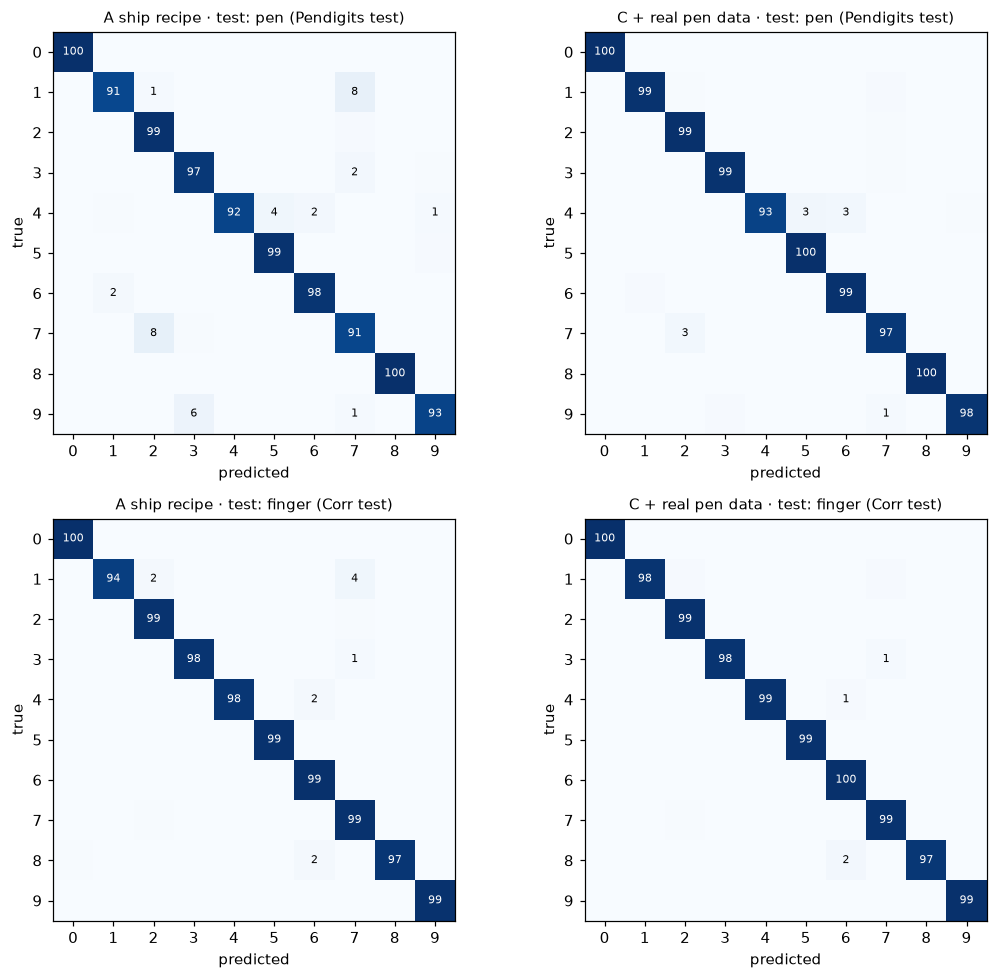

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for r, split in enumerate(['test: pen (Pendigits test)', 'test: finger (Corr test)']):
    x, y = evalsets[split]
    for c, name in enumerate(['A ship recipe', best]):
        _, pred = per_digit([trained[(name, s)] for s in SEEDS], x, y)
        evaluate.plot_confusion(y, pred, f'{name} · {split}', ax=axes[r, c])
plt.tight_layout(); plt.show()

## 7. 在游戏规则下（屏幕上 3 个答案）

In [10]:
game = []
for split in ['test: pen (Pendigits test)', 'test: finger (Corr test)']:
    x, y = evalsets[split]
    for name in ['A ship recipe', best]:
        m = trained[(name, SEEDS[0])]
        acc, wrong, other = evaluate.game_hit_rate(m.predict(x[..., None], batch_size=2048, verbose=0), y, n_answers=3, seed=8)
        game.append({'test set': split, 'config': name, 'accepted %': 100 * acc, 'wrong yokai %': 100 * wrong, 'rewrite / miss %': 100 * other})
pd.DataFrame(game).round(2)

,test set,config,accepted %,wrong yokai %,rewrite / miss %
0,test: pen (Pendigits test),A ship recipe,96.46,1.20,2.34
1,test: pen (Pendigits test),C + real pen data,98.71,0.43,0.86
2,test: finger (Corr test),A ship recipe,98.71,0.43,0.86
3,test: finger (Corr test),C + real pen data,99.19,0.29,0.53


## 8. 保存

In [11]:
out = {'runs': runs.to_dict(orient='records'), 'mean_percent': mean.round(3).to_dict(orient='index'),
       'chosen': best, 'per_digit_test_percent': {f'{a} | {b}': v.tolist() for (a, b), v in digit_table.items()},
       'game_3_answers': game, 'budget': dict(epochs=EPOCHS, steps=STEPS, batch=BATCH, smoothing=SMOOTHING), 'seeds': SEEDS}
(RESULTS / '09_train_with_real.json').write_text(json.dumps(out, indent=2, default=float))
print('saved results/09_train_with_real.json')

saved results/09_train_with_real.json


## 9. 结论与下一步

**按验证数据选中的方案：C（加入真实触控笔数据）。**

测试集结果（两个种子的平均）：

| 方案 | 触控笔 test（14 人） | 手指 test（177 人，未参与训练） | 合成 pad_tmpl |
|---|---|---|---|
| A 上线配方 | 95.55% | 98.27% | 97.12% |
| B + 倾斜 / 笔宽增强 | 94.95% | 97.96% | 96.62% |
| **C + 真实触控笔数据** | **98.17%** | **98.78%** | 96.96% |
| D + 两者 | 97.93% | 98.68% | 96.67% |

（A 是在本 notebook 里用同样的代码重新训练的，手指 test 98.27%，和 notebook 08 里上线模型的 98.36% 一致。）

**1. 加入真实数据效果明显，而且能迁移到另一种工具。**
- 触控笔上，错误率从 4.45% 降到 1.83%（−59%）。这在意料之中，因为训练和测试来自同一个数据集，只是书写者不同。
- 更重要的是**手指**：手指数据完全没参与训练，错误率仍从 1.73% 降到 1.22%（−29%）。两个种子都一致，差距（0.5 个百分点）明显大于种子之间的波动（0.03–0.12）。也就是说，学到的是"真实书写的写法"，而不只是"Pendigits 这 24 个人的写法"。
- 合成测试集 `pad_tmpl` 几乎没变（97.1% → 97.0%），说明它已经测不出这类改进了。今后应以真实测试集为准。

**2. 每个数字（测试集）。**
- 手指上，最大的收益在 **1**（94.3% → 98.3%）和 **4**（97.6% → 98.7%）；**8** 略有下降（97.5% → 97.0%），需要在 notebook 10 里看一下原因。
- 触控笔上，**1、7、9** 提升最大（分别 +7.9、+5.5、+5.3 个百分点）。但 **4** 几乎没变（92.0% → 92.9%）：一笔写成、顶端开口的 4 仍然是最大的难点。

**3. 游戏规则下（屏幕上 3 个答案）。**
- 手指：接受率 98.71% → 99.19%，打错妖怪 0.43% → 0.29%。
- 触控笔：接受率 96.46% → 98.71%，打错妖怪 1.20% → 0.43%。

**4. 倾斜和笔宽增强（B）反而有害。**
- B 在所有测试集上都比 A 差，D 也比 C 略差。
- 从第 3 节的示意图看，一个可能的原因是增强过度：在已经比较粗的笔画上再做膨胀、再加错切，有些字变成了粗糊的一团，不像真实书写。也就是说，notebook 07 看到的"倾斜、笔宽差异"要么不是主要的错误来源，要么需要更温和、更贴近真实的增强。
- 这里没有继续调增强的强度：从 C 的结果看，**真实数据本身**已经提供了这类变化。

**5. 局限。**
- 触控笔的测试只有 14 个人，结论主要看手指（177 人）。
- 只用了两个种子，样本量小，但种子之间的差异明显小于方案之间的差异。
- 方案 C 的 Pendigits 只有 24 个训练书写者，更多样的真实数据（包括我们自己采集的鼠标数据）可能还会有收益。

**下一步：notebook 10，错误审查。**用方案 C 的模型，在手指和触控笔的测试集上把剩下的错误逐个分类："模型确实读错""人眼也认不出""疑似标签错误"，估计真实数据上的准确率上限；同时看一下 8 下降、触控笔上的 4 不动的原因。
